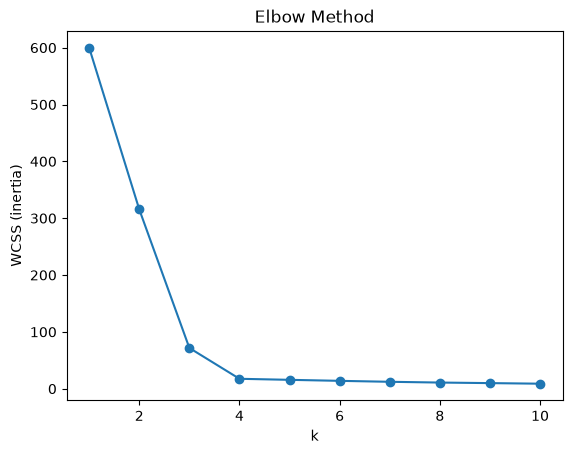

Silhouette: 0.7974739889632732


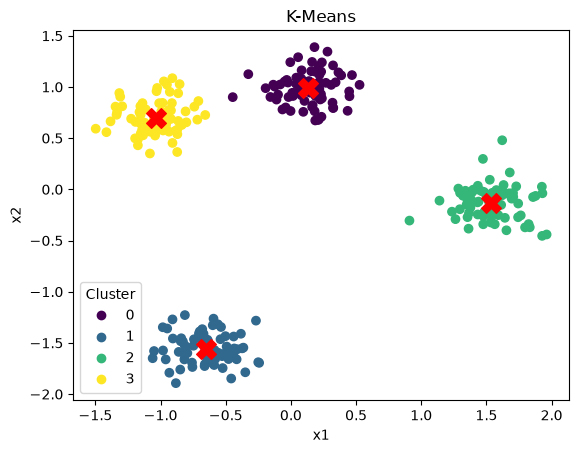

In [1]:
# ===================== REVISION / ONE-SHOT: K-MEANS + ELBOW =====================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1) Generate data (or build a DataFrame from np.random)
X, _ = make_blobs(n_samples=300, centers=4, random_state=42)
X = StandardScaler().fit_transform(X)        # scale when features have different units

# 2) Elbow method: inertia (WCSS) for k = 1..10
wcss = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    wcss.append(km.inertia_)
plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method"); plt.xlabel("k"); plt.ylabel("WCSS (inertia)"); plt.show()

# 3) Final model with chosen k
model = KMeans(n_clusters=4, n_init=10, random_state=42)
labels = model.fit_predict(X)
print("Silhouette:", silhouette_score(X, labels))

# 4) Plot clusters + centroids
sc = plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis")
plt.scatter(model.cluster_centers_[:, 0], model.cluster_centers_[:, 1], c="red", marker="X", s=200, label="Centroids")
plt.legend(*sc.legend_elements(), title="Cluster"); plt.title("K-Means"); plt.xlabel("x1"); plt.ylabel("x2"); plt.show()

# 5) Segment summary: df["Cluster"] = labels; df.groupby("Cluster").mean()

# ---------------- VIVA NOTES ----------------
# K-Means minimizes WCSS = sum of squared distances of points to their cluster centroid.
# Elbow: pick k where WCSS curve bends (adding more clusters gives little gain).
# Silhouette in [-1, 1]: higher = well separated clusters.
# n_init=10 runs K-Means 10 times with different seeds, keeps best (lowest inertia).
# Scale features first: K-Means uses Euclidean distance, big-unit features dominate.
# Weakness: assumes round, similar-size clusters; sensitive to outliers (use K-Medoids / DBSCAN).

### Q8

Write a Python script that implements the Elbow Method to determine the optimal number of clusters for a generated dataset. (Generate dataset of your choice with 14 points)

In [2]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

Shape: (14, 2)


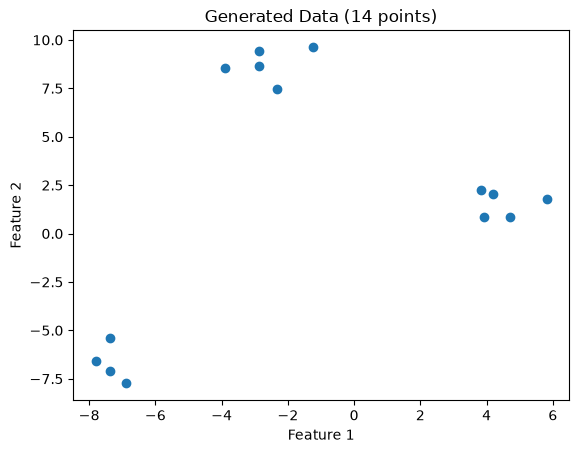

In [3]:
# Generate 14 points in 3 groups
X, _ = make_blobs(n_samples=14, centers=3, cluster_std=0.8, random_state=42)
print("Shape:", X.shape)
plt.scatter(X[:, 0], X[:, 1])
plt.title("Generated Data (14 points)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [4]:
# Elbow method: WCSS (inertia) for k = 1..10
wcss = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    model.fit(X)
    wcss.append(model.inertia_)
    print("k =", k, " WCSS =", round(model.inertia_, 2))

k = 1  WCSS = 868.7
k = 2  WCSS = 271.32
k = 3  WCSS = 14.41
k = 4  WCSS = 11.01
k = 5  WCSS = 8.76
k = 6  WCSS = 6.48
k = 7  WCSS = 4.4
k = 8  WCSS = 2.62
k = 9  WCSS = 1.78


k = 10  WCSS = 0.95


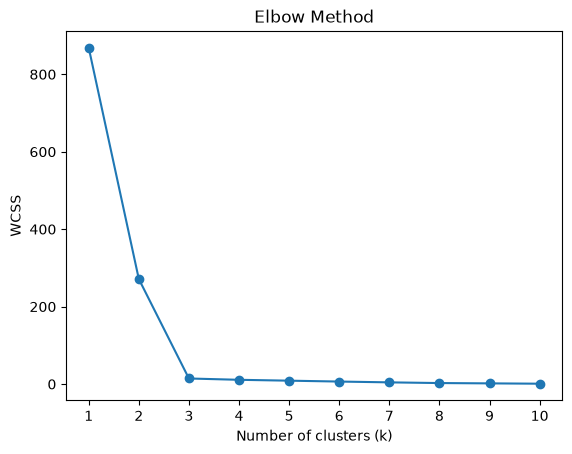

In [5]:
plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of clusters (k)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.show()

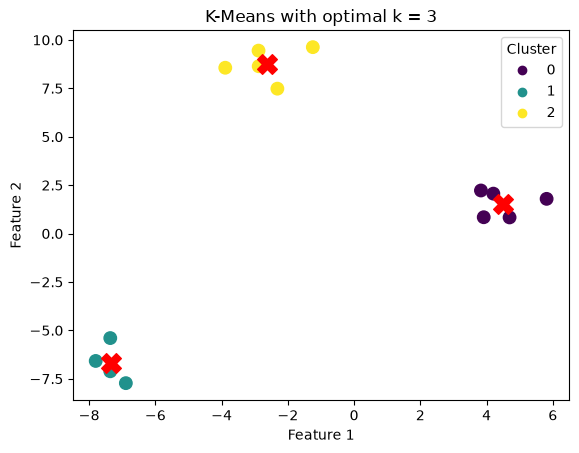

In [6]:
# Bend in the curve is at k = 3, so fit final model with 3 clusters
model = KMeans(n_clusters=3, n_init=10, random_state=42)
labels = model.fit_predict(X)
sc = plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis", s=80)
plt.scatter(model.cluster_centers_[:, 0], model.cluster_centers_[:, 1], c="red", marker="X", s=200, label="Centroids")
plt.legend(*sc.legend_elements(), title="Cluster")
plt.title("K-Means with optimal k = 3")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

### Q11

You are working with an e-commerce company that wants to segment its customers based on their purchasing behaviour. Generate random dataset that includes features like total spending, frequency of purchases, and average basket size. Develop a Python program to perform K-means clustering. Visualize the clusters and summarize the characteristics of each segment.

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [8]:
# Random customer data: 200 customers
np.random.seed(42)
df = pd.DataFrame({
    "total_spending": np.random.randint(500, 50000, 200),
    "purchase_frequency": np.random.randint(1, 50, 200),
    "avg_basket_size": np.random.randint(1, 20, 200),
})
print(df.head())
print(df.describe())

   total_spending  purchase_frequency  avg_basket_size
0           16295                   3                1
1            1360                  49                8
2           38658                  37               14
3           45232                  49               16
4           11784                  17               14
       total_spending  purchase_frequency  avg_basket_size
count      200.000000          200.000000       200.000000
mean     23813.890000           26.325000        10.120000
std      14914.815026           14.149929         5.606493
min        661.000000            1.000000         1.000000
25%      10651.000000           16.750000         5.000000
50%      23032.500000           28.000000        10.000000
75%      37850.250000           37.000000        15.000000
max      49716.000000           49.000000        19.000000


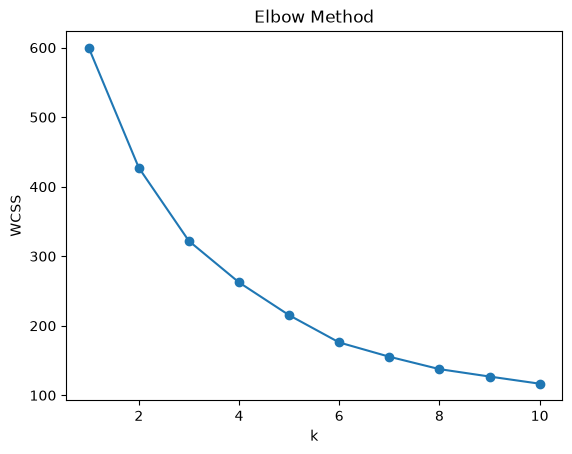

In [9]:
# Scale features (spending is in thousands, frequency is small)
X = StandardScaler().fit_transform(df)

# Elbow method to choose k
wcss = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(X).inertia_ for k in range(1, 11)]
plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method")
plt.xlabel("k")
plt.ylabel("WCSS")
plt.show()

In [10]:
# Fit K-Means with k = 4
model = KMeans(n_clusters=4, n_init=10, random_state=42)
df["Cluster"] = model.fit_predict(X)
print(df["Cluster"].value_counts())

Cluster
0    66
2    48
3    44
1    42
Name: count, dtype: int64


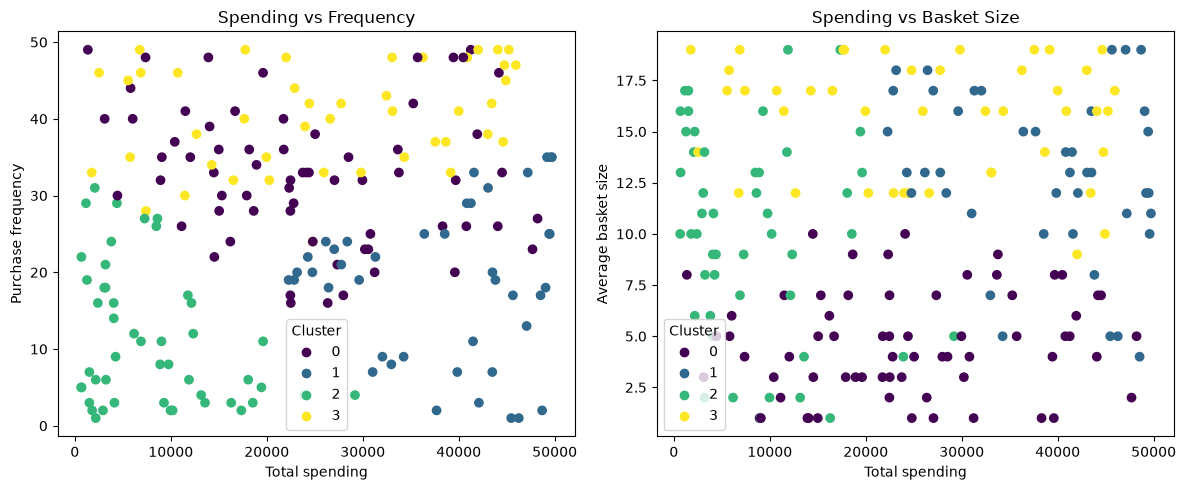

In [11]:
# Visualize: spending vs frequency, and spending vs basket size
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sc = ax[0].scatter(df["total_spending"], df["purchase_frequency"], c=df["Cluster"], cmap="viridis")
ax[0].set_title("Spending vs Frequency")
ax[0].set_xlabel("Total spending")
ax[0].set_ylabel("Purchase frequency")
ax[0].legend(*sc.legend_elements(), title="Cluster")
sc = ax[1].scatter(df["total_spending"], df["avg_basket_size"], c=df["Cluster"], cmap="viridis")
ax[1].set_title("Spending vs Basket Size")
ax[1].set_xlabel("Total spending")
ax[1].set_ylabel("Average basket size")
ax[1].legend(*sc.legend_elements(), title="Cluster")
plt.tight_layout()
plt.show()

In [12]:
# Segment summary: mean of each feature per cluster
summary = df.groupby("Cluster").mean().round(1)
summary["count"] = df["Cluster"].value_counts().sort_index()
print(summary)
# Read the table: high spending + high frequency = loyal VIP, low on all = occasional buyers, etc.

         total_spending  purchase_frequency  avg_basket_size  count
Cluster                                                            
0               24228.5                32.8              4.6     66
1               38177.4                18.6             13.0     42
2                8134.0                11.2             10.1     48
3               26586.7                40.4             15.7     44


### Q12

Use make_blobs to generate 300 samples. Analyse the data and apply KMeans clustering and generate the graph for better representation. Show what happens if you change n_clusters count from 2 to 7(2,3,4,5,6,7)?

In [13]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

Shape: (300, 2)


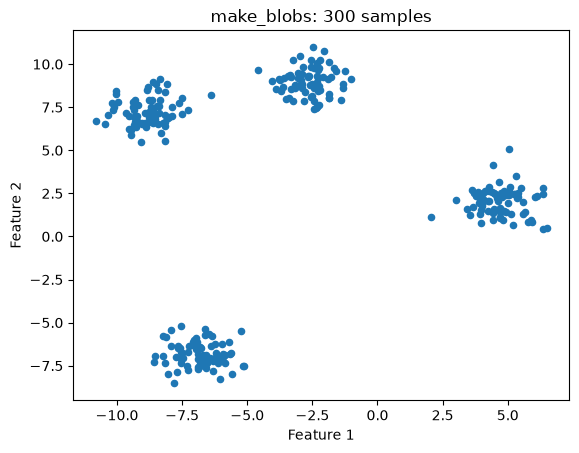

In [14]:
# Generate and look at the data
X, y_true = make_blobs(n_samples=300, centers=4, cluster_std=0.8, random_state=42)
print("Shape:", X.shape)
plt.scatter(X[:, 0], X[:, 1], s=20)
plt.title("make_blobs: 300 samples")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

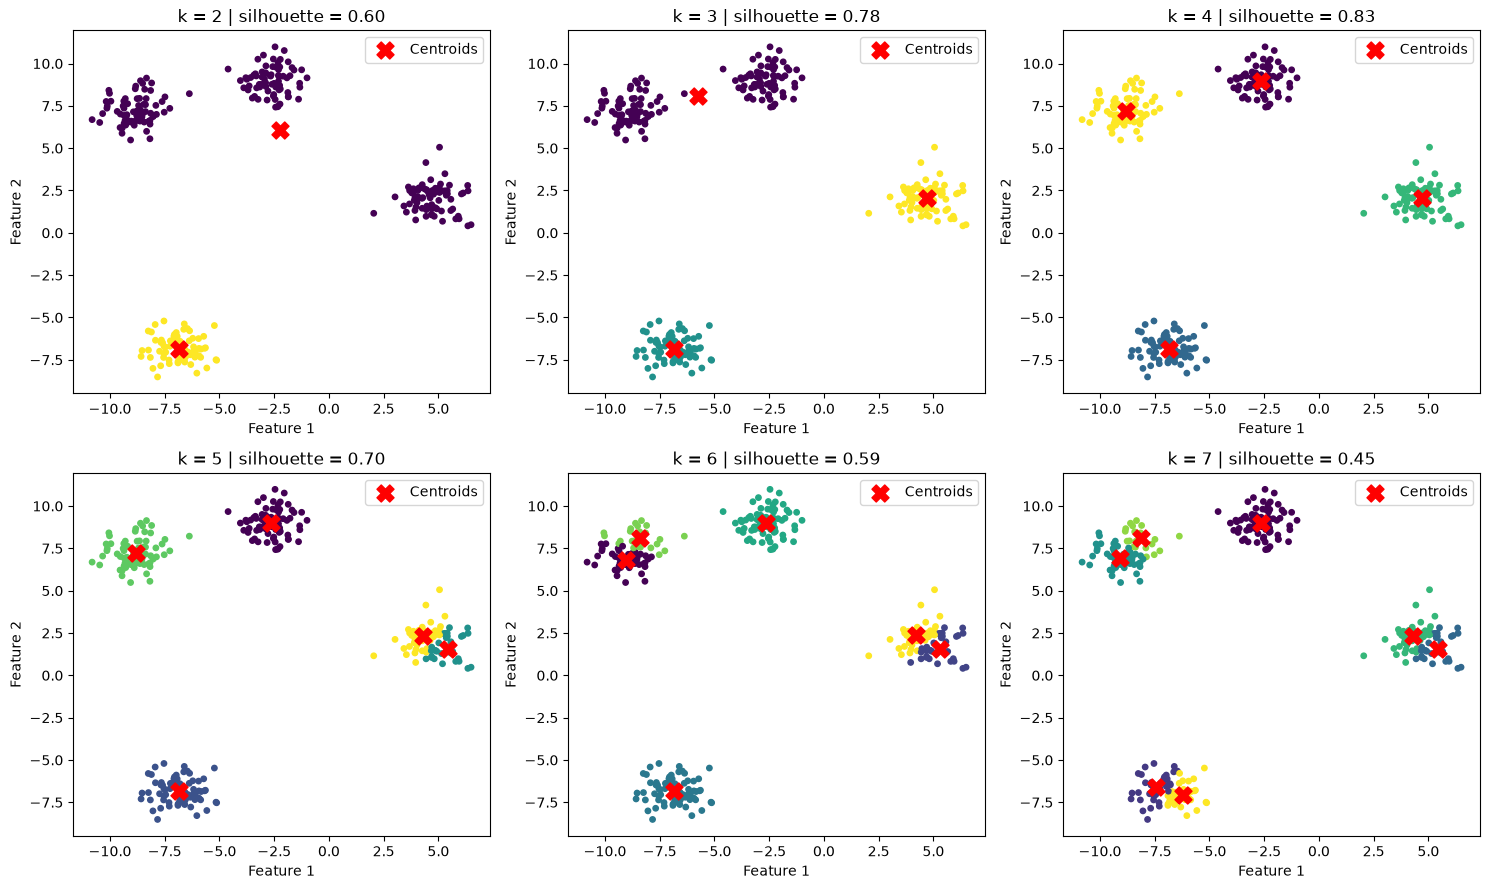

In [15]:
# K-Means for k = 2..7, one subplot each
fig, ax = plt.subplots(2, 3, figsize=(15, 9))
ax = ax.ravel()
wcss, sil = [], []
for i, k in enumerate(range(2, 8)):
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = model.fit_predict(X)
    wcss.append(model.inertia_)
    sil.append(silhouette_score(X, labels))
    ax[i].scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis", s=15)
    ax[i].scatter(model.cluster_centers_[:, 0], model.cluster_centers_[:, 1], c="red", marker="X", s=150, label="Centroids")
    ax[i].set_title(f"k = {k} | silhouette = {sil[-1]:.2f}")
    ax[i].set_xlabel("Feature 1")
    ax[i].set_ylabel("Feature 2")
    ax[i].legend()
plt.tight_layout()
plt.show()

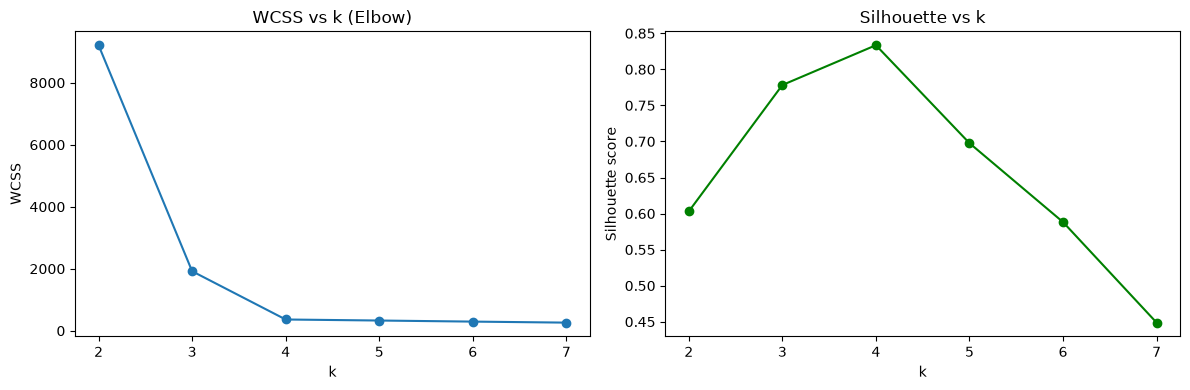

In [16]:
# Effect of k on WCSS and silhouette
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(2, 8), wcss, marker="o")
ax[0].set_title("WCSS vs k (Elbow)")
ax[0].set_xlabel("k")
ax[0].set_ylabel("WCSS")
ax[1].plot(range(2, 8), sil, marker="o", color="green")
ax[1].set_title("Silhouette vs k")
ax[1].set_xlabel("k")
ax[1].set_ylabel("Silhouette score")
plt.tight_layout()
plt.show()
# k = 4 matches the true blobs: elbow bend + highest silhouette. Larger k splits real clusters.

### Q13

A grocery store wants to analyze customer purchase patterns to improve product placements. Generate random transaction data (products purchased together), apply K-means clustering to group similar transactions.

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

In [18]:
# Random transactions: 1 = product bought in that basket, 0 = not bought
# Three shopping habits so that real patterns exist
np.random.seed(42)
products = ["bread", "milk", "eggs", "butter", "chips", "soda", "beer", "apples", "bananas", "spinach"]
habits = {
    "breakfast": [0.9, 0.9, 0.8, 0.7, 0.1, 0.1, 0.05, 0.2, 0.3, 0.1],
    "party":     [0.1, 0.1, 0.1, 0.1, 0.9, 0.9, 0.8, 0.1, 0.1, 0.05],
    "healthy":   [0.2, 0.4, 0.3, 0.1, 0.05, 0.05, 0.05, 0.9, 0.9, 0.8],
}
rows = []
for probs in habits.values():
    rows.append((np.random.rand(70, len(products)) < probs).astype(int))
df = pd.DataFrame(np.vstack(rows), columns=products)
print(df.head())
print("Shape:", df.shape)

   bread  milk  eggs  butter  chips  soda  beer  apples  bananas  spinach
0      1     0     1       1      0     0     0       0        0        0
1      1     0     0       1      0     0     0       0        0        0
2      1     1     1       1      0     0     0       0        0        1
3      1     1     1       0      0     0     0       1        0        0
4      1     1     1       0      0     0     0       0        0        0
Shape: (210, 10)


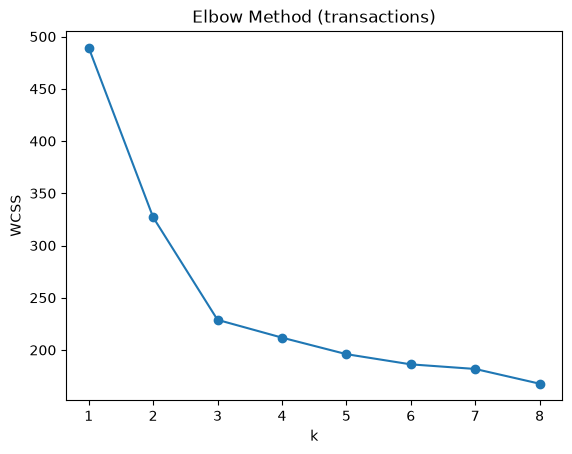

In [19]:
# Elbow method
wcss = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(df).inertia_ for k in range(1, 9)]
plt.plot(range(1, 9), wcss, marker="o")
plt.title("Elbow Method (transactions)")
plt.xlabel("k")
plt.ylabel("WCSS")
plt.show()

In [20]:
# K-Means with k = 3
model = KMeans(n_clusters=3, n_init=10, random_state=42)
df["Cluster"] = model.fit_predict(df[products])
print(df["Cluster"].value_counts())

Cluster
0    73
2    69
1    68
Name: count, dtype: int64


In [21]:
# How often each product appears in each cluster (purchase rate)
profile = df.groupby("Cluster")[products].mean().round(2)
print(profile)
# Products with high rate in the same cluster are bought together -> place them near each other

         bread  milk  eggs  butter  chips  soda  beer  apples  bananas  \
Cluster                                                                  
0         0.12  0.10  0.10    0.10   0.89  0.89  0.81    0.07     0.15   
1         0.28  0.35  0.21    0.09   0.03  0.04  0.09    0.94     0.90   
2         0.91  0.87  0.84    0.77   0.09  0.06  0.06    0.25     0.33   

         spinach  
Cluster           
0           0.07  
1           0.87  
2           0.13  


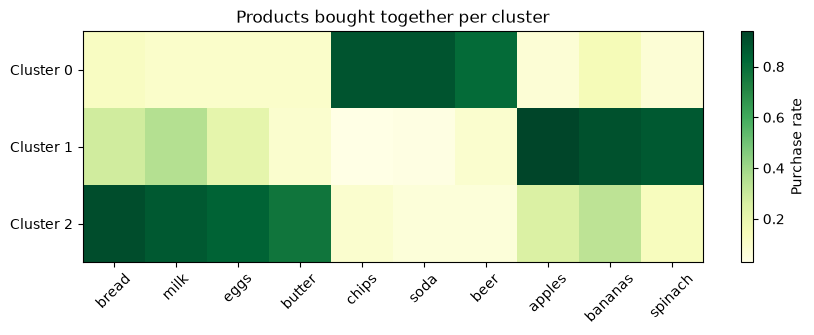

In [22]:
# Heatmap of cluster profiles
plt.figure(figsize=(10, 3))
plt.imshow(profile, cmap="YlGn", aspect="auto")
plt.colorbar(label="Purchase rate")
plt.xticks(range(len(products)), products, rotation=45)
plt.yticks(range(3), [f"Cluster {i}" for i in range(3)])
plt.title("Products bought together per cluster")
plt.show()

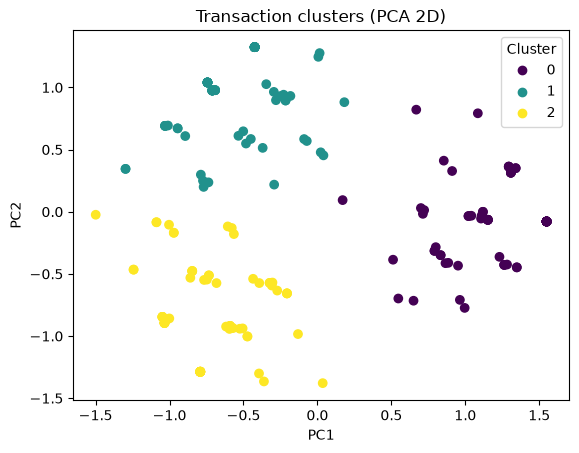

In [23]:
# 2D view of transactions using PCA
X2 = PCA(n_components=2, random_state=42).fit_transform(df[products])
sc = plt.scatter(X2[:, 0], X2[:, 1], c=df["Cluster"], cmap="viridis")
plt.legend(*sc.legend_elements(), title="Cluster")
plt.title("Transaction clusters (PCA 2D)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

### Q14

Generate random dataset with 35 points. Apply KMeans clustering and generate the plot with each cluster points with different colours. What is the impact of varying cluster count? Justify your understanding with suitable graphs.

In [24]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [25]:
# 35 random points around 3 centers
X, _ = make_blobs(n_samples=35, centers=3, cluster_std=1.0, random_state=42)
print("Shape:", X.shape)

Shape: (35, 2)


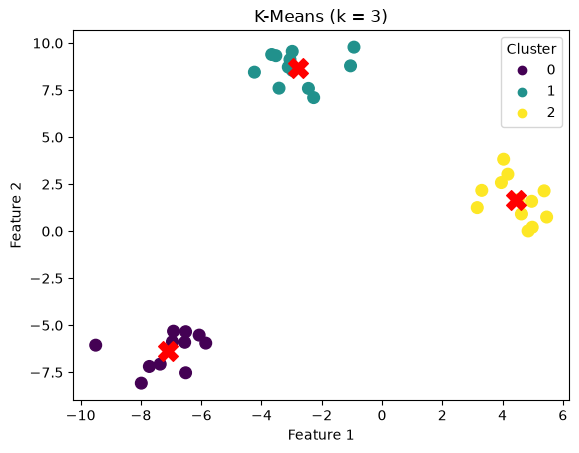

In [26]:
# K-Means with k = 3, each cluster a different colour
model = KMeans(n_clusters=3, n_init=10, random_state=42)
labels = model.fit_predict(X)
sc = plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis", s=70)
plt.scatter(model.cluster_centers_[:, 0], model.cluster_centers_[:, 1], c="red", marker="X", s=200, label="Centroids")
plt.legend(*sc.legend_elements(), title="Cluster")
plt.title("K-Means (k = 3)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

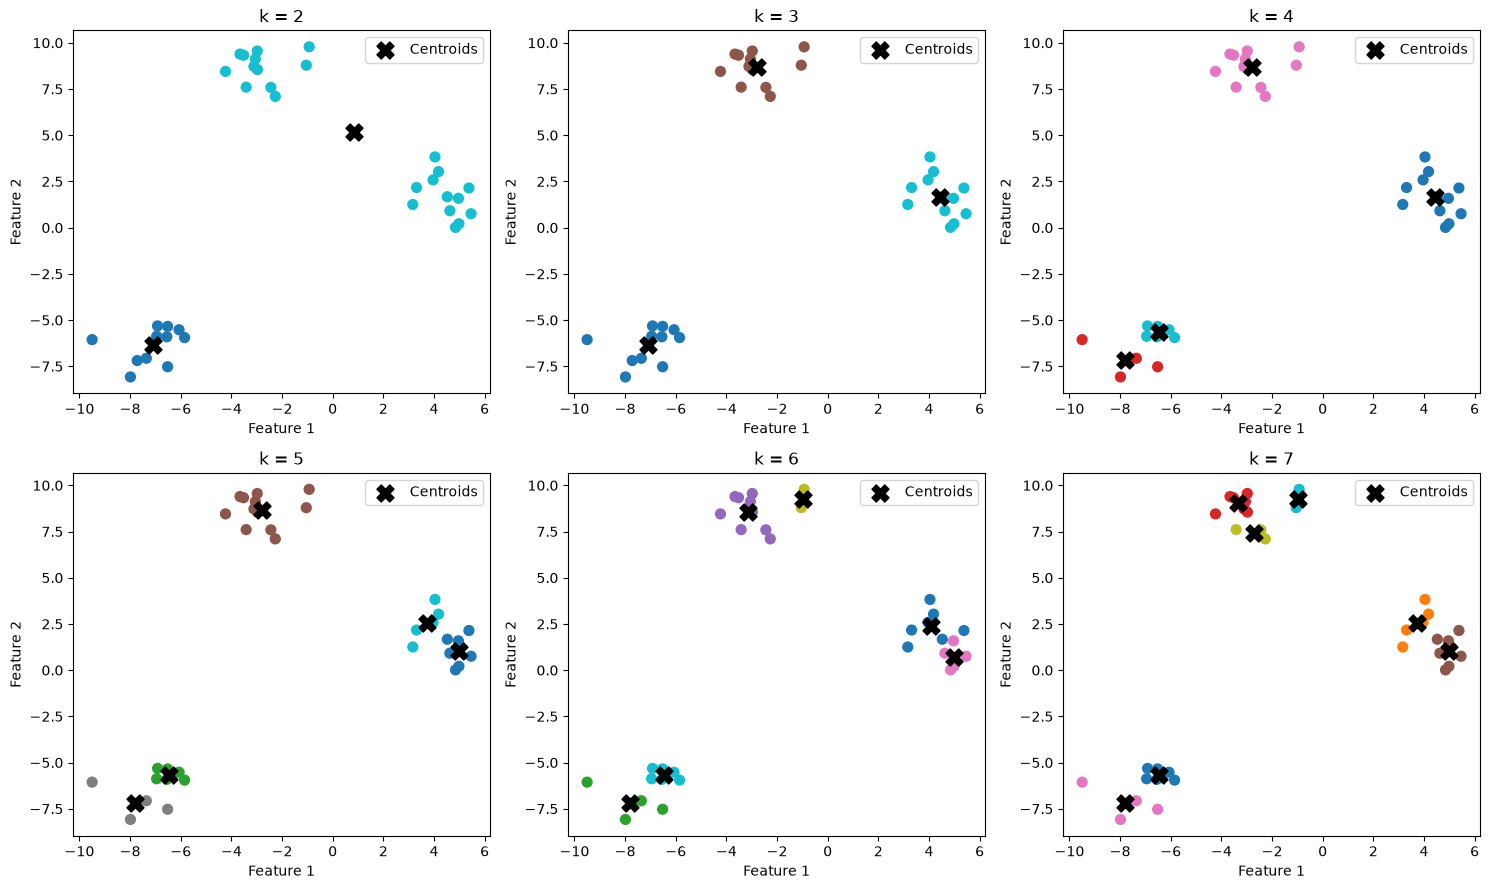

In [27]:
# Impact of varying k: plots for k = 2..7
fig, ax = plt.subplots(2, 3, figsize=(15, 9))
ax = ax.ravel()
wcss, sil = [], []
for i, k in enumerate(range(2, 8)):
    m = KMeans(n_clusters=k, n_init=10, random_state=42)
    lab = m.fit_predict(X)
    wcss.append(m.inertia_)
    sil.append(silhouette_score(X, lab))
    ax[i].scatter(X[:, 0], X[:, 1], c=lab, cmap="tab10", s=50)
    ax[i].scatter(m.cluster_centers_[:, 0], m.cluster_centers_[:, 1], c="black", marker="X", s=150, label="Centroids")
    ax[i].set_title(f"k = {k}")
    ax[i].set_xlabel("Feature 1")
    ax[i].set_ylabel("Feature 2")
    ax[i].legend()
plt.tight_layout()
plt.show()

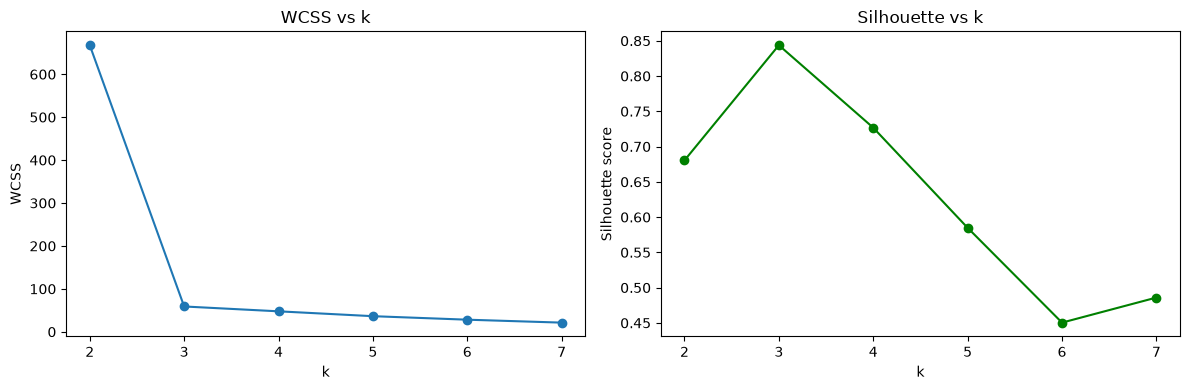

In [28]:
# Justify with WCSS and silhouette curves
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(2, 8), wcss, marker="o")
ax[0].set_title("WCSS vs k")
ax[0].set_xlabel("k")
ax[0].set_ylabel("WCSS")
ax[1].plot(range(2, 8), sil, marker="o", color="green")
ax[1].set_title("Silhouette vs k")
ax[1].set_xlabel("k")
ax[1].set_ylabel("Silhouette score")
plt.tight_layout()
plt.show()
# Small k merges real groups (high WCSS); large k splits real groups (WCSS falls slowly, silhouette drops).
# Best k = elbow point = highest silhouette (k = 3 here).